<a href="https://colab.research.google.com/github/RealHotnCold/MLA0204-192511036/blob/main/9_Compare_LnP_Reg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparing Linear and Polynomial Regression

This notebook demonstrates the differences between **Linear Regression** and **Polynomial Regression** when fitting non-linear data.

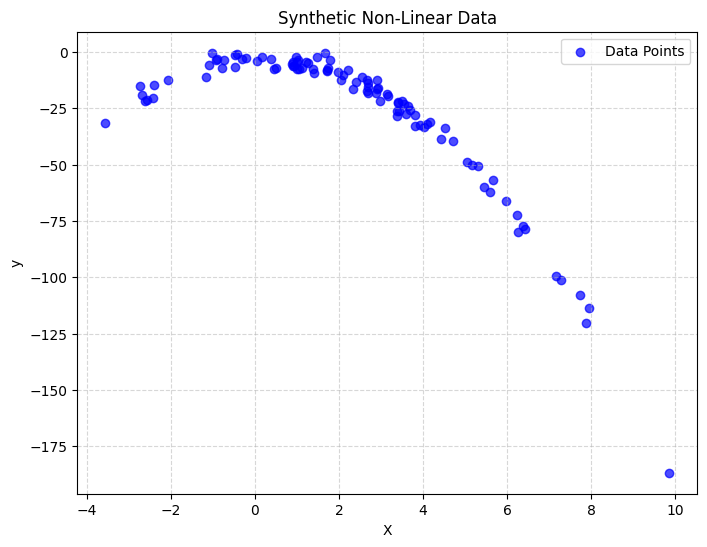

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# 1. Generate synthetic non-linear data (quadratic relationship)
np.random.seed(42)
X = 2 - 3 * np.random.normal(0, 1, 100)
y = X - 2 * (X ** 2) + np.random.normal(-3, 3, 100)

# Reshaping for scikit-learn
X = X[:, np.newaxis]

# Plot the generated data
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color='blue', alpha=0.7, label='Data Points')
plt.title('Synthetic Non-Linear Data')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [2]:
# 2. Fit Simple Linear Regression
linear_model = LinearRegression()
linear_model.fit(X, y)

# 3. Fit Polynomial Regression (Degree 2)
# We use a pipeline to pair PolynomialFeatures with LinearRegression
poly_degree = 2
polynomial_model = make_pipeline(PolynomialFeatures(degree=poly_degree), LinearRegression())
polynomial_model.fit(X, y)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures()),
                ('linearregression', LinearRegression())])

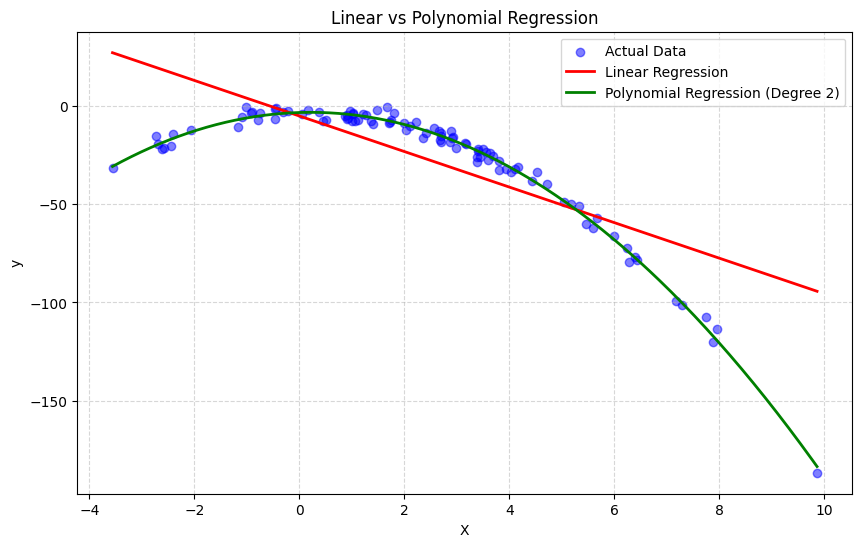

In [3]:
# 4. Predict and Visualize the Comparison

# Create a range of values for X to plot smooth prediction curves
X_seq = np.linspace(X.min(), X.max(), 300)[:, np.newaxis]

y_pred_linear = linear_model.predict(X_seq)
y_pred_poly = polynomial_model.predict(X_seq)

plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', alpha=0.5, label='Actual Data')
plt.plot(X_seq, y_pred_linear, color='red', linewidth=2, label='Linear Regression')
plt.plot(X_seq, y_pred_poly, color='green', linewidth=2, label=f'Polynomial Regression (Degree {poly_degree})')

plt.title('Linear vs Polynomial Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()